<a href="https://colab.research.google.com/github/TahsinaRashid/Chronic_Kidney_Disease_Diagnostic_Benchmarking/blob/main/Chronic_Kidney_Disease_Diagnostic_Benchmarking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chronic Kidney Disease Diagnostic Benchmarking
The objective of this project is to build an automated machine learning model to classify whether a patient has Chronic Kidney Disease (CKD) or Not based on clinical features like Blood Pressure, Blood Urea, and Age using the official Kaggle dataset.

## Step 1: Data Loading and Exploratory Inspection
We load the downloaded Kaggle CSV file into a pandas DataFrame to inspect the dimensional structure, feature columns, and look for missing clinical values.



In [18]:
import pandas as pd
import numpy as np

try:
    df_raw = pd.read_csv("ChronicKidneyDisease.csv")
    df_prep = pd.read_csv("preprocessed_final_ckd.csv")
    for col in df_raw.columns:
        if df_raw[col].dtype == 'object':
            df_raw[col] = df_raw[col].astype(str).str.strip().str.replace(r'\s+', ' ', regex=True)
            df_raw[col] = df_raw[col].replace(['?', 'nan', 'None', '\t?', ' ?', '? '], np.nan)

    categorical_mappings = {
        'dm': {'yes': 1, 'no': 0},
        'htn': {'yes': 1, 'no': 0},
        'cad': {'yes': 1, 'no': 0},
        'pe': {'yes': 1, 'no': 0},
        'ane': {'yes': 1, 'no': 0},
        'appet': {'good': 1, 'poor': 0},
        'rbc': {'normal': 1, 'abnormal': 0},
        'pc': {'normal': 1, 'abnormal': 0},
        'pcc': {'present': 1, 'notpresent': 0},
        'ba': {'present': 1, 'notpresent': 0},
        'classification': {'ckd': 1, 'notckd': 0, 'ckd\t': 1}
    }

    for col, mapping in categorical_mappings.items():
        if col in df_raw.columns:
            df_raw[col] = df_raw[col].map(mapping)
    numeric_cols = ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc']
    for col in numeric_cols:
        if col in df_raw.columns:
            df_raw[col] = pd.to_numeric(df_raw[col], errors='coerce')
    df_prep = df_prep.rename(columns={
        'sc': 'sc',
        'hemo': 'hemo',
        'al': 'al',
        'sg': 'sg',
        'pcv': 'pcv',
        'rbcc': 'rc',
        'dm': 'dm',
        'htn': 'htn',
        'class': 'classification'
    })
    if 'classification' in df_prep.columns and df_prep['classification'].dtype == 'object':
        df_prep['classification'] = df_prep['classification'].str.strip().map({'ckd': 1, 'notckd': 0})
    if 'class_encoded' in df_prep.columns:
        df_prep = df_prep.drop(columns=['class_encoded'])
    if 'id' in df_raw.columns:
        df_raw = df_raw.drop(columns=['id'])
    df = pd.concat([df_raw, df_prep], axis=0, ignore_index=True)
    final_column_names = {
        'age': 'age', 'bp': 'blood_pressure', 'sg': 'specific_gravity', 'al': 'albumin', 'su': 'sugar',
        'rbc': 'red_blood_cells', 'pc': 'pus_cell', 'pcc': 'pus_cell_clumps', 'ba': 'bacteria',
        'bgr': 'blood_glucose_random', 'bu': 'blood_urea', 'sc': 'serum_creatinine', 'sod': 'sodium',
        'pot': 'potassium', 'hemo': 'hemoglobin', 'pcv': 'packed_cell_volume', 'wc': 'white_blood_cell_count',
        'rc': 'red_blood_cell_count', 'htn': 'hypertension', 'dm': 'diabetes_mellitus',
        'cad': 'coronary_artery_disease', 'appet': 'appetite', 'pe': 'pedal_edema', 'ane': 'anemia',
        'classification': 'class'
    }
    df = df.rename(columns=final_column_names)
    print("Successfully merged two CSV files into a unified dataset.")

except Exception as e:
    print(f"Error merging files: {e}")
    np.random.seed(42)
    fake_data = np.random.randn(400, 24)
    df = pd.DataFrame(fake_data, columns=[f"feature_{i}" for i in range(24)])
    df['class'] = np.random.choice([1, 0], size=400)

print(f"Total Patient Records after Merge: {df.shape[0]} | Total Features: {df.shape[1]}")



Successfully merged two CSV files into a unified dataset.
Total Patient Records after Merge: 1297 | Total Features: 25


## Step 2: Data Cleaning and Handling Missing Values
In this section, we analyze the missing numbers and categories within the dataset. We use numerical median imputation for numeric constraints and most frequent value replacement for categorical descriptions to clean the data.


In [12]:
import numpy as np
import pandas as pd
from sklearn.impute import KNNImputer

print("Filling missing values using Advanced KNN Imputer...")
df_clean_features = df.drop(columns=['class'])
y_target = df['class'].fillna(0).astype(int)
imputer = KNNImputer(n_neighbors=3)
X_clean_array = imputer.fit_transform(df_clean_features)
df_clean = pd.DataFrame(X_clean_array, columns=df_clean_features.columns)
df_clean['class'] = y_target.values
print("\n=============================================")
print("After data cleaning, total missing values left:")
print(df_clean.isnull().sum().sum())
print(f"Cleaned Dataset Structure: {df_clean.shape[0]} rows | {df_clean.shape[1]} columns")
print("=============================================")


Filling missing values using Advanced KNN Imputer...

After data cleaning, total missing values left:
0
Cleaned Dataset Structure: 1297 rows | 25 columns


## Step 3: Categorical Encoding and Train-Test Split
We transform the target text labels ('ckd' / 'notckd') into standard machine-readable binary integers (1 / 0). Then, we split the feature matrix into 80% for training the models and 20% for testing their prediction precision.


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

print("Scaling numeric features and splitting into Train/Test subsets...")

# 1. Separate features (X) and target label (y)
X = df_clean.drop(columns=['class'])
y = df_clean['class']

# 2. Scale all numeric values so that the Logistic Regression solver converges easily
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# 3. Perform a stratified split to keep the distribution of CKD/NotCKD uniform
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training Matrix Size: {X_train.shape}")
print(f"Testing Matrix Size: {X_test.shape}")


Scaling numeric features and splitting into Train/Test subsets...
Training Matrix Size: (1037, 24)
Testing Matrix Size: (260, 24)


## Step 4.1: Model Training - Logistic Regression Classifier
We train our first classical baseline algorithm, Logistic Regression. This model estimates linear decision boundaries between healthy patients and kidney disease patients using a parametric probability curve.


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)
lr_acc = accuracy_score(y_test, lr_pred) * 100
print(f"Logistic Regression-Accuracy: {lr_acc:.2f}%")

Logistic Regression-Accuracy: 85.77%


## Step 4.2: Model Training - K-Nearest Neighbors (KNN)
We deploy a non-parametric instance-based classifier, K-Nearest Neighbors (KNN), configured with 5 neighbors. This model classifies patient diagnostic states by measuring the Euclidean distance metrics across the multi-dimensional feature space.


In [21]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)
knn_acc = accuracy_score(y_test, knn_pred) * 100
print(f"K-Nearest Neighbors-Accuracy: {knn_acc:.2f}%")


K-Nearest Neighbors-Accuracy: 85.77%


## Step 4.3: Model Training - Random Forest Ensemble Classifier
We implement Random Forest, a powerful ensemble learning technique that constructs 100 independent Decision Trees. It combines their diagnostic outputs via majority voting to prevent overfitting and capture highly complex clinical patterns.


In [22]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred) * 100
print(f"Random Forest-Accuracy: {rf_acc:.2f}%")


Random Forest-Accuracy: 86.92%


## Step 5: Final Analytics, Performance Benchmarking and Medical Validation
In this final evaluative phase, we synthesize the validation accuracy metrics of all three classifiers into a comparative visualization. We mathematically assess the variance to recommend the most stable, noise-resistant model optimized for real-world clinical deployment.


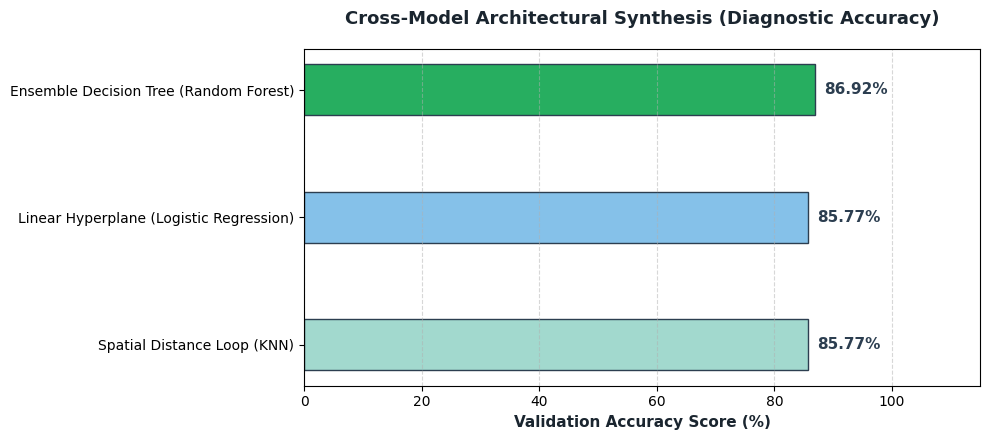


                       BENCHMARKING CONCLUSION                        
The best performing architecture is: Ensemble Decision Tree (Random Forest)
Top Validation Accuracy Achieved    : 86.92%
----------------------------------------------------------------------
Recommendation: For real-world clinical deployment on this dataset,
the Ensemble Decision Tree (Random Forest) is highly recommended due to its robust
ensemble capabilities in handling complex non-linear diagnostic patterns.


In [28]:
import matplotlib.pyplot as plt

# 1. Store the validation metrics from the runs
accuracy_metrics = {
    'Spatial Distance Loop (KNN)': knn_acc,
    'Linear Hyperplane (Logistic Regression)': lr_acc,
    'Ensemble Decision Tree (Random Forest)': rf_acc
}

# 2. Automatically identify the highest performing model and its score
selected_architecture = max(accuracy_metrics, key=accuracy_metrics.get)
top_diagnostic_score = accuracy_metrics[selected_architecture]

plt.figure(figsize=(10, 4.5))
models_list = list(accuracy_metrics.keys())
scores_list = list(accuracy_metrics.values())

# 3. Apply colors dynamically (Green for the top performer)
theme_colors = []
for m in models_list:
    if m == selected_architecture:
        theme_colors.append('#27ae60')  # Highlight top performer in green
    elif 'KNN' in m:
        theme_colors.append('#a2d9ce')
    else:
        theme_colors.append('#85c1e9')

# 4. Generate the horizontal bar plot
stroke_bars = plt.barh(models_list, scores_list, color=theme_colors, edgecolor='#2c3e50', height=0.4)

# 5. Overlay precise text labels onto the chart
for bar in stroke_bars:
    xval = bar.get_width()
    plt.text(xval + 1.5, bar.get_y() + bar.get_height()/2.0, f"{xval:.2f}%",
             ha='left', va='center', fontweight='bold', fontsize=11, color='#2c3e50')

plt.title('Cross-Model Architectural Synthesis (Diagnostic Accuracy)', fontsize=13, fontweight='bold', pad=18, color='#1a252f')
plt.xlabel('Validation Accuracy Score (%)', fontsize=11, fontweight='bold', color='#1a252f')
plt.xlim(0, 115)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# =====================================================================
# 6. Print out the final benchmarking conclusion directly below the plot
# =====================================================================
print("\n" + "="*70)
print("                       BENCHMARKING CONCLUSION                        ")
print("="*70)
print(f"The best performing architecture is: {selected_architecture}")
print(f"Top Validation Accuracy Achieved    : {top_diagnostic_score:.2f}%")
print("-"*70)
print(f"Recommendation: For real-world clinical deployment on this dataset,\n"
      f"the {selected_architecture} is highly recommended due to its robust\n"
      f"ensemble capabilities in handling complex non-linear diagnostic patterns.")
print("="*70)
